In [40]:
import os
import random
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf

from tensorflow import keras
from tensorflow.keras import layers, models

# Set random seed
SEED = 42
random.seed(SEED)
np.random.seed(SEED)
tf.random.set_seed(SEED)

# Check GPU
gpus = tf.config.list_physical_devices('GPU')

if gpus:
    print("GPU detected successfully!")

    for gpu in gpus:
        tf.config.experimental.set_memory_growth(
            gpu, True
        )

    print("Available GPU:", gpus)

else:
    print("WARNING: GPU not detected!")
    print("Please enable GPU in Kaggle Settings.")

print("TensorFlow Version:", tf.__version__)
print("GPU Available:", len(gpus))

GPU detected successfully!
Available GPU: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU'), PhysicalDevice(name='/physical_device:GPU:1', device_type='GPU')]
TensorFlow Version: 2.21.0
GPU Available: 2


In [41]:
import os
import time
import random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf

from pathlib import Path
from sklearn.utils.class_weight import compute_class_weight
from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    ConfusionMatrixDisplay
)

from tensorflow.keras import layers, models
from tensorflow.keras.applications import (
    MobileNetV2,
    ResNet50,
    DenseNet121
)

from tensorflow.keras.callbacks import (
    ModelCheckpoint,
    ReduceLROnPlateau
)

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
tf.random.set_seed(SEED)

print("TensorFlow version:", tf.__version__)
print("GPU available:", tf.config.list_physical_devices('GPU'))

TensorFlow version: 2.21.0
GPU available: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU'), PhysicalDevice(name='/physical_device:GPU:1', device_type='GPU')]


In [42]:
import os

for root, dirs, files in os.walk("/kaggle/input"):
    print(root)
    print("Folders:", dirs[:10])
    print()

/kaggle/input
Folders: ['datasets']

/kaggle/input/datasets
Folders: ['paultimothymooney']

/kaggle/input/datasets/paultimothymooney
Folders: ['chest-xray-pneumonia']

/kaggle/input/datasets/paultimothymooney/chest-xray-pneumonia
Folders: ['chest_xray']

/kaggle/input/datasets/paultimothymooney/chest-xray-pneumonia/chest_xray
Folders: ['__MACOSX', 'chest_xray', 'test', 'train', 'val']

/kaggle/input/datasets/paultimothymooney/chest-xray-pneumonia/chest_xray/__MACOSX
Folders: ['chest_xray']

/kaggle/input/datasets/paultimothymooney/chest-xray-pneumonia/chest_xray/__MACOSX/chest_xray
Folders: ['test', 'train', 'val']

/kaggle/input/datasets/paultimothymooney/chest-xray-pneumonia/chest_xray/__MACOSX/chest_xray/test
Folders: ['NORMAL', 'PNEUMONIA']

/kaggle/input/datasets/paultimothymooney/chest-xray-pneumonia/chest_xray/__MACOSX/chest_xray/test/NORMAL
Folders: []

/kaggle/input/datasets/paultimothymooney/chest-xray-pneumonia/chest_xray/__MACOSX/chest_xray/test/PNEUMONIA
Folders: []

/kagg

In [43]:
import os
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

import tensorflow as tf

from tensorflow.keras import layers, models
from tensorflow.keras.applications import VGG16, ResNet50, DenseNet121
from tensorflow.keras.applications.vgg16 import preprocess_input as vgg_preprocess
from tensorflow.keras.applications.resnet50 import preprocess_input as resnet_preprocess
from tensorflow.keras.applications.densenet import preprocess_input as densenet_preprocess

from tensorflow.keras.callbacks import EarlyStopping, ReduceLROnPlateau
from tensorflow.keras.optimizers import Adam

from sklearn.metrics import classification_report, confusion_matrix, accuracy_score, precision_score, recall_score, f1_score
from sklearn.utils.class_weight import compute_class_weight

print("TensorFlow version:", tf.__version__)
print("GPU:", tf.config.list_physical_devices("GPU"))




TensorFlow version: 2.21.0
GPU: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU'), PhysicalDevice(name='/physical_device:GPU:1', device_type='GPU')]


In [44]:
import os

print("Files/Folders inside /kaggle/input:")

for item in os.listdir("/kaggle/input"):
    print(item)

Files/Folders inside /kaggle/input:
datasets


In [45]:
import os
import time
import gc
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import tensorflow as tf

from tensorflow.keras import layers, models
from tensorflow.keras.applications import VGG16, ResNet50, DenseNet121
from tensorflow.keras.applications.vgg16 import preprocess_input as vgg_preprocess
from tensorflow.keras.applications.resnet50 import preprocess_input as resnet_preprocess
from tensorflow.keras.applications.densenet import preprocess_input as densenet_preprocess

from tensorflow.keras.callbacks import ReduceLROnPlateau
from tensorflow.keras.optimizers import Adam

from sklearn.metrics import classification_report, confusion_matrix
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score
from sklearn.utils.class_weight import compute_class_weight

DATASET_DIR = "/kaggle/input/datasets/paultimothymooney/chest-xray-pneumonia/chest_xray/chest_xray"

TRAIN_DIR = os.path.join(DATASET_DIR, "train")
VAL_DIR = os.path.join(DATASET_DIR, "val")
TEST_DIR = os.path.join(DATASET_DIR, "test")

print("Train:", TRAIN_DIR)
print("Validation:", VAL_DIR)
print("Test:", TEST_DIR)

print()
print("Train classes:", os.listdir(TRAIN_DIR))
print("Validation classes:", os.listdir(VAL_DIR))
print("Test classes:", os.listdir(TEST_DIR))


Train: /kaggle/input/datasets/paultimothymooney/chest-xray-pneumonia/chest_xray/chest_xray/train
Validation: /kaggle/input/datasets/paultimothymooney/chest-xray-pneumonia/chest_xray/chest_xray/val
Test: /kaggle/input/datasets/paultimothymooney/chest-xray-pneumonia/chest_xray/chest_xray/test

Train classes: ['.DS_Store', 'NORMAL', 'PNEUMONIA']
Validation classes: ['.DS_Store', 'NORMAL', 'PNEUMONIA']
Test classes: ['.DS_Store', 'NORMAL', 'PNEUMONIA']


In [46]:
IMG_SIZE = (224, 224)
BATCH_SIZE = 32
EPOCHS = 30
SEED = 42

np.random.seed(SEED)
tf.random.set_seed(SEED)

print("Image size:", IMG_SIZE)
print("Batch size:", BATCH_SIZE)
print("Epochs:", EPOCHS)

Image size: (224, 224)
Batch size: 32
Epochs: 30


In [47]:
train_dataset = tf.keras.utils.image_dataset_from_directory(
    TRAIN_DIR,
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    label_mode="binary",
    shuffle=True,
    seed=SEED
)

val_dataset = tf.keras.utils.image_dataset_from_directory(
    VAL_DIR,
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    label_mode="binary",
    shuffle=False
)

test_dataset = tf.keras.utils.image_dataset_from_directory(
    TEST_DIR,
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    label_mode="binary",
    shuffle=False
)

class_names = train_dataset.class_names

print("Classes:", class_names)

Found 5216 files belonging to 2 classes.
Found 16 files belonging to 2 classes.
Found 624 files belonging to 2 classes.
Classes: ['NORMAL', 'PNEUMONIA']


In [48]:
AUTOTUNE = tf.data.AUTOTUNE

train_dataset = train_dataset.prefetch(AUTOTUNE)
val_dataset = val_dataset.prefetch(AUTOTUNE)
test_dataset = test_dataset.prefetch(AUTOTUNE)

print("Dataset pipeline ready.")

Dataset pipeline ready.


In [49]:
class_counts = {}

for class_name in class_names:
    class_path = os.path.join(TRAIN_DIR, class_name)
    
    count = 0
    
    for root, dirs, files in os.walk(class_path):
        for file in files:
            if file.lower().endswith((".jpg", ".jpeg", ".png", ".bmp")):
                count += 1
    
    class_counts[class_name] = count

print("Class counts:")
print(class_counts)

class_indices = {
    class_name: index
    for index, class_name in enumerate(class_names)
}

weight_labels = []

for class_name, count in class_counts.items():
    weight_labels.extend(
        [class_indices[class_name]] * count
    )

weight_values = compute_class_weight(
    class_weight="balanced",
    classes=np.unique(weight_labels),
    y=weight_labels
)

class_weights = {
    index: float(weight)
    for index, weight in enumerate(weight_values)
}

print("Class weights:")
print(class_weights)

Class counts:
{'NORMAL': 1341, 'PNEUMONIA': 3875}
Class weights:
{0: 1.9448173005219984, 1: 0.6730322580645162}


In [50]:
data_augmentation = tf.keras.Sequential(
    [
        layers.RandomFlip("horizontal"),
        layers.RandomRotation(0.05),
        layers.RandomZoom(0.10),
        layers.RandomContrast(0.10)
    ],
    name="data_augmentation"
)

print("Data augmentation ready.")

Data augmentation ready.


In [51]:
def create_model(model_name, fine_tuning=False):
    
    if model_name == "VGG16":
        base_model = VGG16(
            weights="imagenet",
            include_top=False,
            input_shape=(224, 224, 3)
        )
        preprocess_function = vgg_preprocess
        
    elif model_name == "ResNet50":
        base_model = ResNet50(
            weights="imagenet",
            include_top=False,
            input_shape=(224, 224, 3)
        )
        preprocess_function = resnet_preprocess
        
    elif model_name == "DenseNet121":
        base_model = DenseNet121(
            weights="imagenet",
            include_top=False,
            input_shape=(224, 224, 3)
        )
        preprocess_function = densenet_preprocess
        
    else:
        raise ValueError("Invalid model name")
    
    if fine_tuning:
        for layer in base_model.layers:
            layer.trainable = False
        
        start_layer = int(len(base_model.layers) * 0.70)
        
        for layer in base_model.layers[start_layer:]:
            if not isinstance(layer, layers.BatchNormalization):
                layer.trainable = True
        
        learning_rate = 0.00001
        
    else:
        base_model.trainable = False
        learning_rate = 0.0001
    
    inputs = layers.Input(shape=(224, 224, 3))
    
    x = data_augmentation(inputs)
    x = layers.Lambda(preprocess_function)(x)
    
    x = base_model(x, training=False)
    
    x = layers.GlobalAveragePooling2D()(x)
    x = layers.BatchNormalization()(x)
    x = layers.Dropout(0.5)(x)
    x = layers.Dense(128, activation="relu")(x)
    x = layers.Dropout(0.3)(x)
    outputs = layers.Dense(1, activation="sigmoid")(x)
    
    model = models.Model(
        inputs=inputs,
        outputs=outputs
    )
    
    model.compile(
        optimizer=Adam(learning_rate=learning_rate),
        loss="binary_crossentropy",
        metrics=[
            "accuracy",
            tf.keras.metrics.Precision(name="precision"),
            tf.keras.metrics.Recall(name="recall")
        ]
    )
    
    return model

In [57]:
def get_callbacks():
    
    reduce_lr = ReduceLROnPlateau(
        monitor="val_loss",
        factor=0.3,
        patience=3,
        min_lr=0.0000001,
        verbose=1
    )
    
    return [reduce_lr]

In [53]:
def plot_history(history, model_name, mode):
    
    epochs_range = range(
        1,
        len(history.history["accuracy"]) + 1
    )
    
    plt.figure(figsize=(8, 5))
    
    plt.plot(
        epochs_range,
        history.history["accuracy"],
        label="Training Accuracy"
    )
    
    plt.plot(
        epochs_range,
        history.history["val_accuracy"],
        label="Validation Accuracy"
    )
    
    plt.xlabel("Epoch")
    plt.ylabel("Accuracy")
    plt.title(model_name + " - " + mode + " Accuracy")
    plt.legend()
    plt.grid(True)
    plt.show()
    
    plt.figure(figsize=(8, 5))
    
    plt.plot(
        epochs_range,
        history.history["loss"],
        label="Training Loss"
    )
    
    plt.plot(
        epochs_range,
        history.history["val_loss"],
        label="Validation Loss"
    )
    
    plt.xlabel("Epoch")
    plt.ylabel("Loss")
    plt.title(model_name + " - " + mode + " Loss")
    plt.legend()
    plt.grid(True)
    plt.show()

In [54]:
def evaluate_model(model, model_name, mode, history, training_time):
    
    testing_start = time.time()
    
    probabilities = model.predict(
        test_dataset,
        verbose=1
    ).ravel()
    
    testing_time = time.time() - testing_start
    
    predictions = (probabilities >= 0.5).astype(int)
    
    true_labels = np.concatenate(
        [
            labels.numpy().astype(int).ravel()
            for images, labels in test_dataset
        ]
    )
    
    accuracy = accuracy_score(
        true_labels,
        predictions
    )
    
    precision = precision_score(
        true_labels,
        predictions,
        zero_division=0
    )
    
    recall = recall_score(
        true_labels,
        predictions,
        zero_division=0
    )
    
    f1 = f1_score(
        true_labels,
        predictions,
        zero_division=0
    )
    
    print()
    print("=" * 70)
    print(model_name, "-", mode)
    print("=" * 70)
    
    print("Accuracy :", round(accuracy, 4))
    print("Precision:", round(precision, 4))
    print("Recall   :", round(recall, 4))
    print("F1 Score :", round(f1, 4))
    print("Training Time:", round(training_time, 2), "seconds")
    print("Testing Time :", round(testing_time, 2), "seconds")
    
    print()
    print("Classification Report")
    
    print(
        classification_report(
            true_labels,
            predictions,
            target_names=class_names,
            digits=4,
            zero_division=0
        )
    )
    
    cm = confusion_matrix(
        true_labels,
        predictions
    )
    
    plt.figure(figsize=(7, 5))
    
    sns.heatmap(
        cm,
        annot=True,
        fmt="d",
        cmap="Blues",
        xticklabels=class_names,
        yticklabels=class_names
    )
    
    plt.xlabel("Predicted Label")
    plt.ylabel("True Label")
    plt.title(
        model_name + " - " + mode + " Confusion Matrix"
    )
    
    plt.show()
    
    plot_history(
        history,
        model_name,
        mode
    )
    
    return {
        "Model": model_name,
        "Mode": mode,
        "Accuracy": accuracy,
        "Precision": precision,
        "Recall": recall,
        "F1": f1,
        "Training Time": training_time,
        "Testing Time": testing_time,
        "Epochs": len(history.history["loss"])
    }

In [59]:
def train_and_evaluate(model_name, fine_tuning):
    
    tf.keras.backend.clear_session()
    gc.collect()
    
    if fine_tuning:
        mode = "Fine-Tuning"
    else:
        mode = "Without Fine-Tuning"
    
    print()
    print("=" * 80)
    print("MODEL:", model_name)
    print("MODE:", mode)
    print("=" * 80)
    
    model = create_model(
        model_name,
        fine_tuning
    )
    
    trainable_count = np.sum(
        [
            np.prod(variable.shape)
            for variable in model.trainable_weights
        ]
    )
    
    print("Trainable parameters:", trainable_count)
    
    training_start = time.time()
    
    history = model.fit(
        train_dataset,
        validation_data=val_dataset,
        epochs=EPOCHS,
        class_weight=class_weights,
        callbacks=get_callbacks(),
        verbose=1
    )
    
    training_time = time.time() - training_start
    
    result = evaluate_model(
        model,
        model_name,
        mode,
        history,
        training_time
    )
    
    filename = (
        model_name.lower()
        + "_"
        + mode.lower().replace(" ", "_").replace("-", "_")
        + ".keras"
    )
    
    model.save(filename)
    
    print()
    print("Saved model:", filename)
    
    del model
    del history
    
    tf.keras.backend.clear_session()
    gc.collect()
    
    return result


MODEL: VGG16
MODE: Without Fine-Tuning
58889256/58889256 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
Trainable parameters: 66817
Epoch 1/30
163/163 ━━━━━━━━━━━━━━━━━━━━ 70s 367ms/step - accuracy: 0.6835 - loss: 0.5807 - precision: 0.9109 - recall: 0.6361 - val_accuracy: 0.6875 - val_loss: 0.4844 - val_precision: 1.0000 - val_recall: 0.3750 - learning_rate: 1.0000e-04
Epoch 2/30
163/163 ━━━━━━━━━━━━━━━━━━━━ 28s 170ms/step - accuracy: 0.8355 - loss: 0.3670 - precision: 0.9559 - recall: 0.8163 - val_accuracy: 0.9375 - val_loss: 0.2845 - val_precision: 1.0000 - val_recall: 0.8750 - learning_rate: 1.0000e-04
Epoch 3/30
163/163 ━━━━━━━━━━━━━━━━━━━━ 27s 164ms/step - accuracy: 0.8737 - loss: 0.2848 - precision: 0.9631 - recall: 0.8630 - val_accuracy: 0.9375 - val_loss: 0.2271 - val_precision: 1.0000 - val_recall: 0.8750 - learning_rate: 1.0000e-04
Epoch 4/30
163/163 ━━━━━━━━━━━━━━━━━━━━ 27s 164ms/step - accuracy: 0.8894 - loss: 0.2587 - precision: 0.9658 - recall: 0.8823 - val_accuracy: 0.9375 - val_los

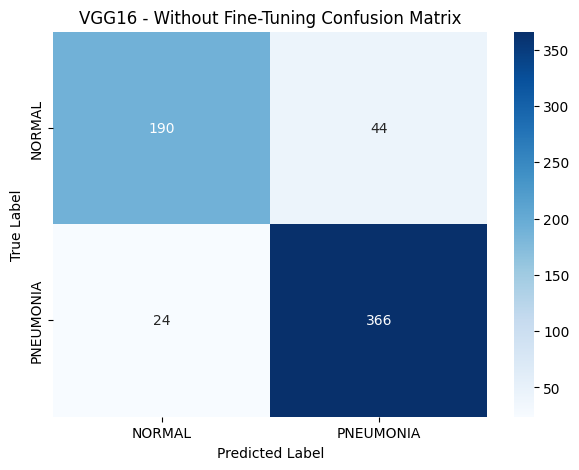

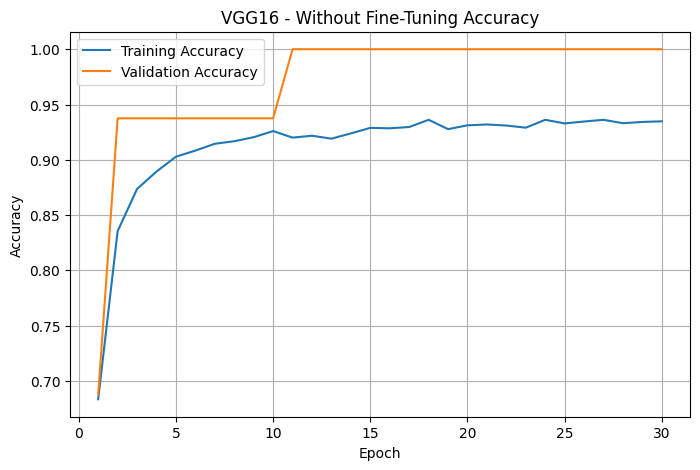

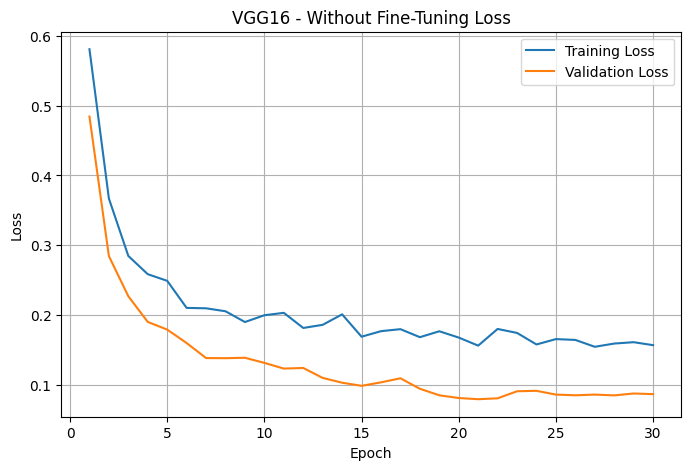


Saved model: vgg16_without_fine_tuning.keras


In [60]:
vgg16_no_ft_result = train_and_evaluate(
    "VGG16",
    False
)

In [61]:
vgg16_ft_result = train_and_evaluate(
    "VGG16",
    True
)


MODEL: VGG16
MODE: Fine-Tuning
Trainable parameters: 9506049
Epoch 1/30


KeyboardInterrupt: 

In [62]:
def create_model(model_name, fine_tuning=False):
    
    if model_name == "VGG16":
        base_model = VGG16(
            weights="imagenet",
            include_top=False,
            input_shape=(224, 224, 3)
        )
        preprocess_function = vgg_preprocess
        
    elif model_name == "ResNet50":
        base_model = ResNet50(
            weights="imagenet",
            include_top=False,
            input_shape=(224, 224, 3)
        )
        preprocess_function = resnet_preprocess
        
    elif model_name == "DenseNet121":
        base_model = DenseNet121(
            weights="imagenet",
            include_top=False,
            input_shape=(224, 224, 3)
        )
        preprocess_function = densenet_preprocess
        
    else:
        raise ValueError("Invalid model name")
    
    base_model.trainable = False
    
    if fine_tuning:
        
        if model_name == "VGG16":
            fine_tune_layers = 4
            
        elif model_name == "ResNet50":
            fine_tune_layers = 10
            
        else:
            fine_tune_layers = 10
        
        for layer in base_model.layers[-fine_tune_layers:]:
            if not isinstance(layer, layers.BatchNormalization):
                layer.trainable = True
        
        learning_rate = 0.00001
        
    else:
        learning_rate = 0.0001
    
    inputs = layers.Input(shape=(224, 224, 3))
    
    x = data_augmentation(inputs)
    x = layers.Lambda(preprocess_function)(x)
    
    x = base_model(x, training=False)
    
    x = layers.GlobalAveragePooling2D()(x)
    x = layers.BatchNormalization()(x)
    x = layers.Dropout(0.5)(x)
    x = layers.Dense(128, activation="relu")(x)
    x = layers.Dropout(0.3)(x)
    outputs = layers.Dense(1, activation="sigmoid")(x)
    
    model = models.Model(
        inputs=inputs,
        outputs=outputs
    )
    
    model.compile(
        optimizer=Adam(learning_rate=learning_rate),
        loss="binary_crossentropy",
        metrics=[
            "accuracy",
            tf.keras.metrics.Precision(name="precision"),
            tf.keras.metrics.Recall(name="recall")
        ]
    )
    
    return model

In [63]:
test_model = create_model(
    "VGG16",
    True
)

test_model.summary()

trainable_parameters = np.sum(
    [
        np.prod(variable.shape)
        for variable in test_model.trainable_weights
    ]
)

print("Trainable parameters:", trainable_parameters)

del test_model

tf.keras.backend.clear_session()
gc.collect()

Model: "functional_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_3 (InputLayer)      │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ data_augmentation (Sequential)  │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lambda_1 (Lambda)               │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ vgg16 (Functional)              │ (None, 7, 7, 512)      │    14,714,688 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d_1      │ (None, 512)            │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 512)            │         2,048 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 512)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 128)            │        65,664 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_3 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 1)              │           129 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 14,782,529 (56.39 MB)

 Trainable params: 7,146,241 (27.26 MB)

 Non-trainable params: 7,636,288 (29.13 MB)

Trainable parameters: 7146241


0


MODEL: VGG16
MODE: Fine-Tuning
Trainable parameters: 7146241
Epoch 1/30
163/163 ━━━━━━━━━━━━━━━━━━━━ 38s 207ms/step - accuracy: 0.6635 - loss: 0.5550 - precision: 0.9593 - recall: 0.5714 - val_accuracy: 0.8125 - val_loss: 0.4195 - val_precision: 1.0000 - val_recall: 0.6250 - learning_rate: 1.0000e-05
Epoch 2/30
163/163 ━━━━━━━━━━━━━━━━━━━━ 31s 187ms/step - accuracy: 0.8278 - loss: 0.3092 - precision: 0.9885 - recall: 0.7773 - val_accuracy: 0.9375 - val_loss: 0.1995 - val_precision: 1.0000 - val_recall: 0.8750 - learning_rate: 1.0000e-05
Epoch 3/30
163/163 ━━━━━━━━━━━━━━━━━━━━ 31s 188ms/step - accuracy: 0.8785 - loss: 0.2275 - precision: 0.9906 - recall: 0.8444 - val_accuracy: 1.0000 - val_loss: 0.0717 - val_precision: 1.0000 - val_recall: 1.0000 - learning_rate: 1.0000e-05
Epoch 4/30
163/163 ━━━━━━━━━━━━━━━━━━━━ 32s 196ms/step - accuracy: 0.9062 - loss: 0.1907 - precision: 0.9896 - recall: 0.8831 - val_accuracy: 1.0000 - val_loss: 0.0433 - val_precision: 1.0000 - val_recall: 1.0000 - 

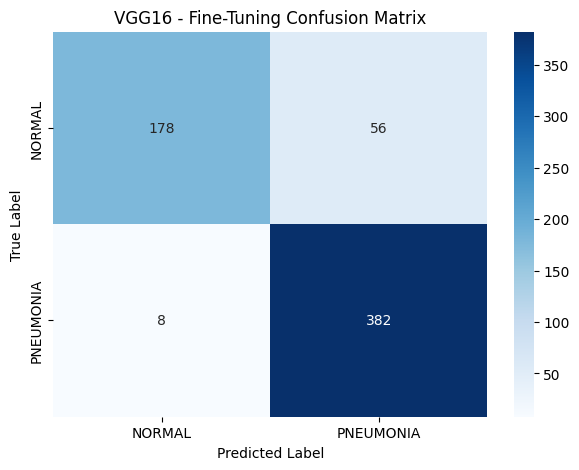

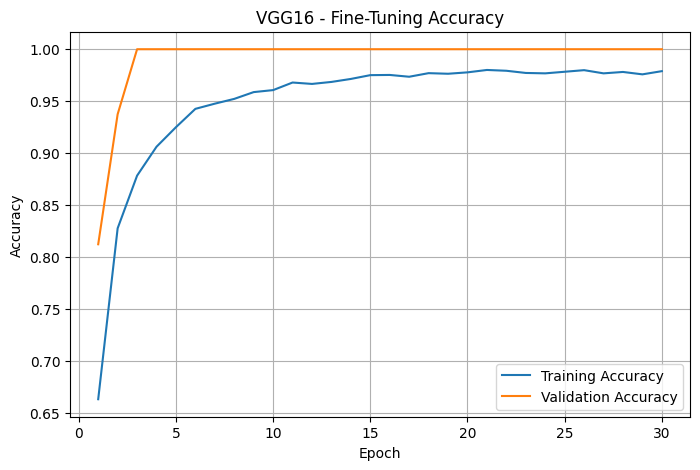

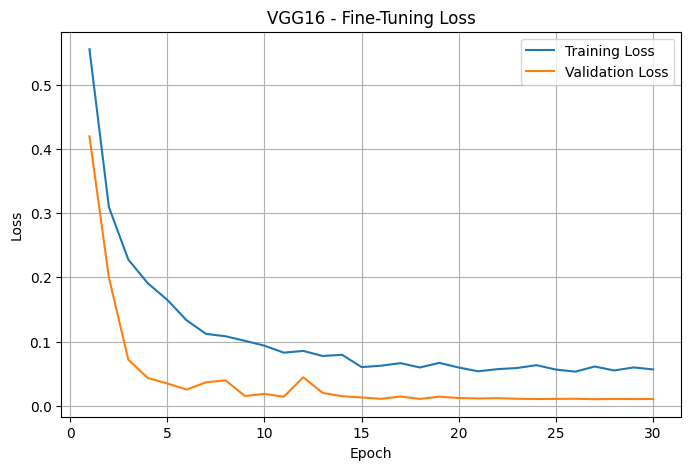


Saved model: vgg16_fine_tuning.keras


In [64]:
vgg16_ft_result = train_and_evaluate(
    "VGG16",
    True
)


MODEL: ResNet50
MODE: Without Fine-Tuning
94765736/94765736 ━━━━━━━━━━━━━━━━━━━━ 1s 0us/step
Trainable parameters: 266497
Epoch 1/30
163/163 ━━━━━━━━━━━━━━━━━━━━ 37s 175ms/step - accuracy: 0.8478 - loss: 0.3423 - precision: 0.9578 - recall: 0.8317 - val_accuracy: 0.8125 - val_loss: 0.3025 - val_precision: 0.7778 - val_recall: 0.8750 - learning_rate: 1.0000e-04
Epoch 2/30
163/163 ━━━━━━━━━━━━━━━━━━━━ 25s 151ms/step - accuracy: 0.9082 - loss: 0.2149 - precision: 0.9740 - recall: 0.9004 - val_accuracy: 0.8750 - val_loss: 0.2857 - val_precision: 0.8000 - val_recall: 1.0000 - learning_rate: 1.0000e-04
Epoch 3/30
163/163 ━━━━━━━━━━━━━━━━━━━━ 24s 149ms/step - accuracy: 0.9218 - loss: 0.1811 - precision: 0.9787 - recall: 0.9146 - val_accuracy: 0.8750 - val_loss: 0.2228 - val_precision: 0.8000 - val_recall: 1.0000 - learning_rate: 1.0000e-04
Epoch 4/30
163/163 ━━━━━━━━━━━━━━━━━━━━ 25s 151ms/step - accuracy: 0.9325 - loss: 0.1736 - precision: 0.9796 - recall: 0.9285 - val_accuracy: 0.8750 - val

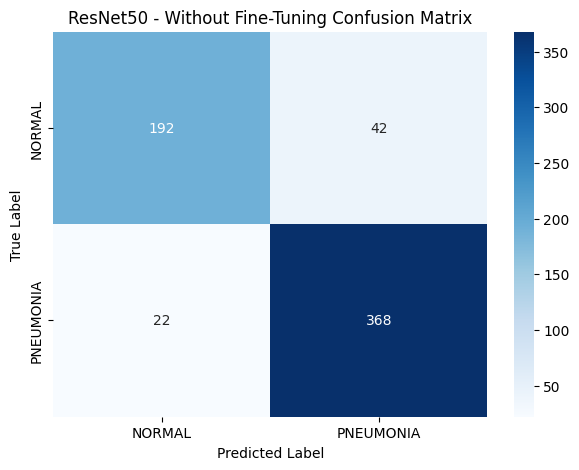

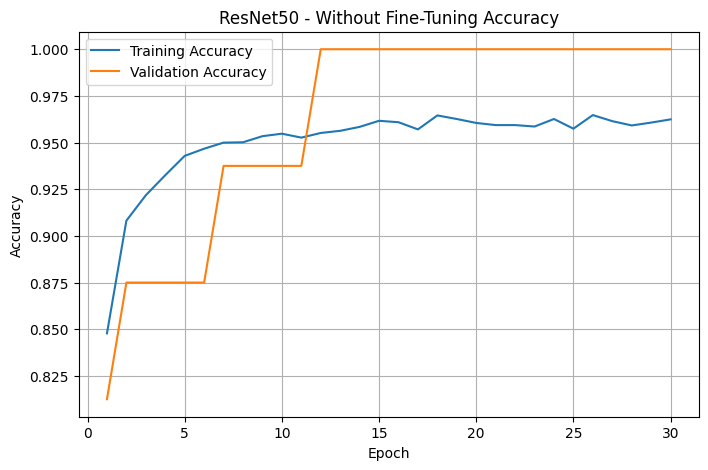

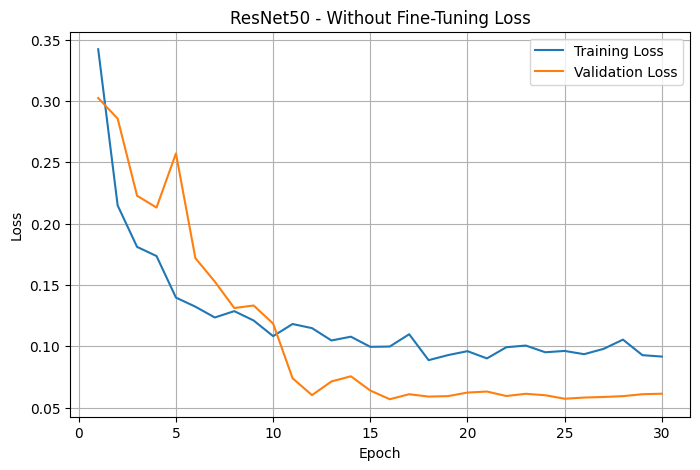


Saved model: resnet50_without_fine_tuning.keras


In [65]:
resnet50_result = train_and_evaluate(
    "ResNet50",
    False
)


MODEL: ResNet50
MODE: Fine-Tuning
Trainable parameters: 4726017
Epoch 1/30
163/163 ━━━━━━━━━━━━━━━━━━━━ 38s 180ms/step - accuracy: 0.6415 - loss: 0.6386 - precision: 0.9618 - recall: 0.5388 - val_accuracy: 0.9375 - val_loss: 0.4012 - val_precision: 1.0000 - val_recall: 0.8750 - learning_rate: 1.0000e-05
Epoch 2/30
163/163 ━━━━━━━━━━━━━━━━━━━━ 27s 165ms/step - accuracy: 0.8192 - loss: 0.3508 - precision: 0.9867 - recall: 0.7670 - val_accuracy: 0.8125 - val_loss: 0.2978 - val_precision: 0.7778 - val_recall: 0.8750 - learning_rate: 1.0000e-05
Epoch 3/30
163/163 ━━━━━━━━━━━━━━━━━━━━ 26s 160ms/step - accuracy: 0.8815 - loss: 0.2638 - precision: 0.9863 - recall: 0.8524 - val_accuracy: 0.8750 - val_loss: 0.3423 - val_precision: 0.8000 - val_recall: 1.0000 - learning_rate: 1.0000e-05
Epoch 4/30
163/163 ━━━━━━━━━━━━━━━━━━━━ 27s 163ms/step - accuracy: 0.9030 - loss: 0.2171 - precision: 0.9839 - recall: 0.8839 - val_accuracy: 0.8750 - val_loss: 0.4090 - val_precision: 0.8000 - val_recall: 1.0000

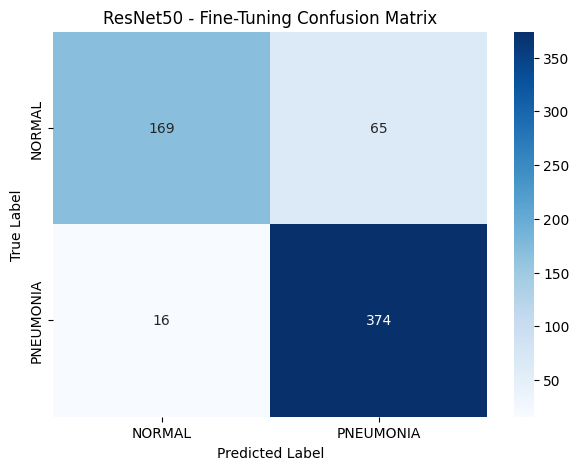

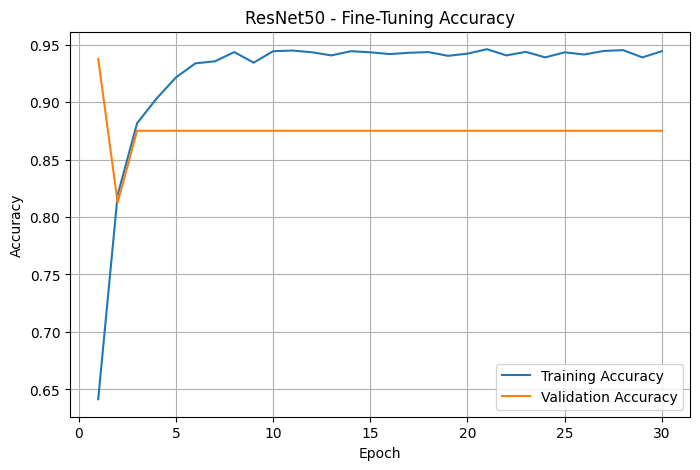

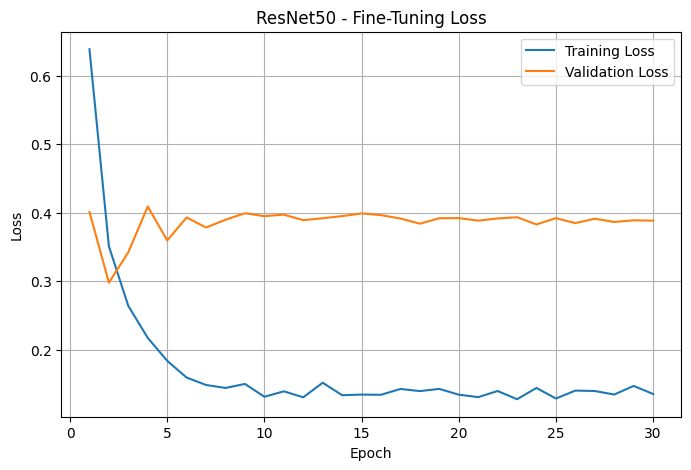


Saved model: resnet50_fine_tuning.keras


In [66]:
resnet50_ft_result = train_and_evaluate(
    "ResNet50",
    True
)


MODEL: DenseNet121
MODE: Without Fine-Tuning
29084464/29084464 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
Trainable parameters: 133377
Epoch 1/30
163/163 ━━━━━━━━━━━━━━━━━━━━ 46s 196ms/step - accuracy: 0.7761 - loss: 0.5152 - precision: 0.8963 - recall: 0.7899 - val_accuracy: 0.8750 - val_loss: 0.3342 - val_precision: 1.0000 - val_recall: 0.7500 - learning_rate: 1.0000e-04
Epoch 2/30
163/163 ━━━━━━━━━━━━━━━━━━━━ 27s 163ms/step - accuracy: 0.8631 - loss: 0.2934 - precision: 0.9650 - recall: 0.8465 - val_accuracy: 0.8750 - val_loss: 0.2421 - val_precision: 0.8750 - val_recall: 0.8750 - learning_rate: 1.0000e-04
Epoch 3/30
163/163 ━━━━━━━━━━━━━━━━━━━━ 26s 160ms/step - accuracy: 0.9001 - loss: 0.2294 - precision: 0.9719 - recall: 0.8914 - val_accuracy: 0.8750 - val_loss: 0.2072 - val_precision: 0.8750 - val_recall: 0.8750 - learning_rate: 1.0000e-04
Epoch 4/30
163/163 ━━━━━━━━━━━━━━━━━━━━ 27s 163ms/step - accuracy: 0.9112 - loss: 0.2060 - precision: 0.9747 - recall: 0.9040 - val_accuracy: 0.8750 - 

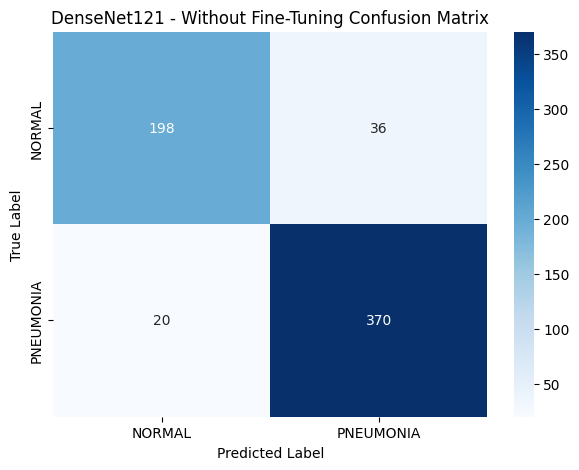

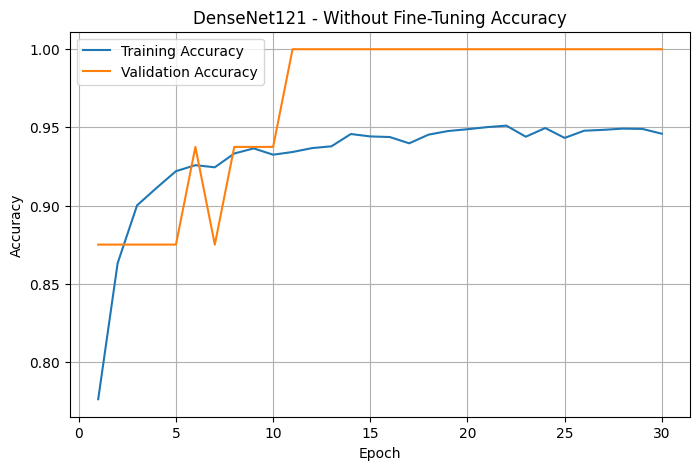

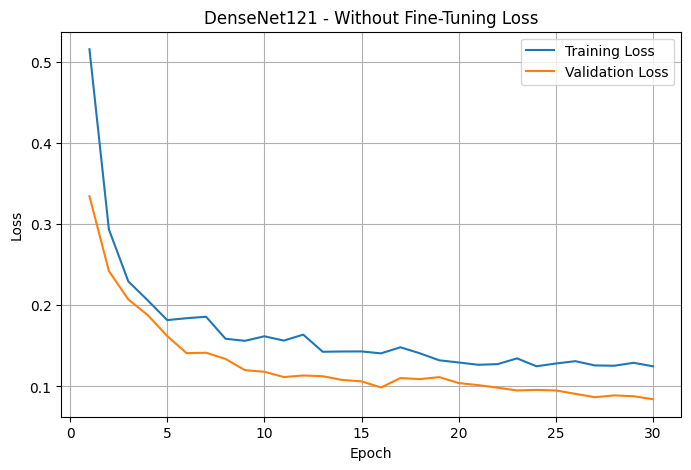


Saved model: densenet121_without_fine_tuning.keras


In [67]:
densenet121_result = train_and_evaluate(
    "DenseNet121",
    False
)


MODEL: DenseNet121
MODE: Fine-Tuning
Trainable parameters: 297217
Epoch 1/30
163/163 ━━━━━━━━━━━━━━━━━━━━ 46s 195ms/step - accuracy: 0.5201 - loss: 0.7392 - precision: 0.8854 - recall: 0.4067 - val_accuracy: 0.6875 - val_loss: 0.5643 - val_precision: 0.8000 - val_recall: 0.5000 - learning_rate: 1.0000e-05
Epoch 2/30
163/163 ━━━━━━━━━━━━━━━━━━━━ 27s 164ms/step - accuracy: 0.6043 - loss: 0.5976 - precision: 0.9389 - recall: 0.4999 - val_accuracy: 0.7500 - val_loss: 0.4399 - val_precision: 0.8333 - val_recall: 0.6250 - learning_rate: 1.0000e-05
Epoch 3/30
163/163 ━━━━━━━━━━━━━━━━━━━━ 27s 162ms/step - accuracy: 0.6741 - loss: 0.5047 - precision: 0.9560 - recall: 0.5884 - val_accuracy: 0.8125 - val_loss: 0.3664 - val_precision: 0.8571 - val_recall: 0.7500 - learning_rate: 1.0000e-05
Epoch 4/30
163/163 ━━━━━━━━━━━━━━━━━━━━ 27s 163ms/step - accuracy: 0.7312 - loss: 0.4389 - precision: 0.9736 - recall: 0.6560 - val_accuracy: 0.8125 - val_loss: 0.3096 - val_precision: 0.8571 - val_recall: 0.75

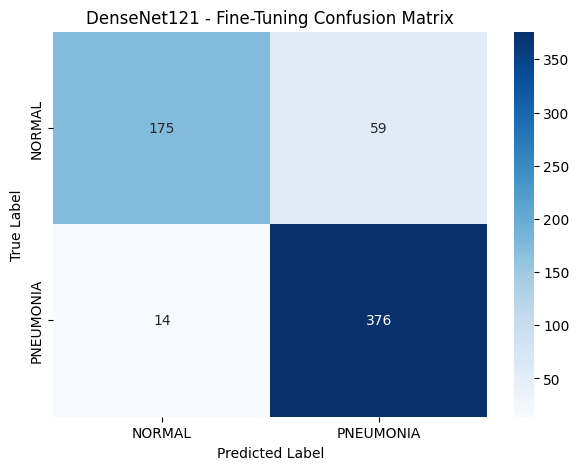

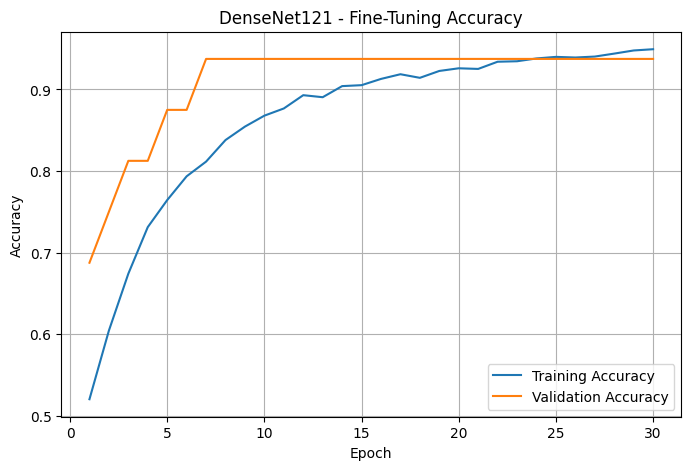

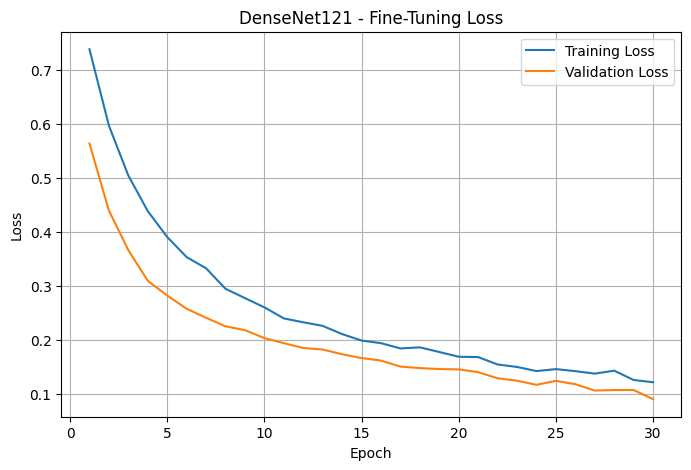


Saved model: densenet121_fine_tuning.keras


In [68]:
densenet121_ft_result = train_and_evaluate(
    "DenseNet121",
    True
)


MODEL: VGG16
MODE: Without Fine-Tuning
Trainable parameters: 66817
Epoch 1/30
163/163 ━━━━━━━━━━━━━━━━━━━━ 31s 176ms/step - accuracy: 0.6913 - loss: 0.5912 - precision: 0.9205 - recall: 0.6397 - val_accuracy: 0.8125 - val_loss: 0.4371 - val_precision: 1.0000 - val_recall: 0.6250 - learning_rate: 1.0000e-04
Epoch 2/30
163/163 ━━━━━━━━━━━━━━━━━━━━ 28s 169ms/step - accuracy: 0.8397 - loss: 0.3490 - precision: 0.9595 - recall: 0.8188 - val_accuracy: 0.8750 - val_loss: 0.2154 - val_precision: 1.0000 - val_recall: 0.7500 - learning_rate: 1.0000e-04
Epoch 3/30
163/163 ━━━━━━━━━━━━━━━━━━━━ 26s 161ms/step - accuracy: 0.8746 - loss: 0.2836 - precision: 0.9632 - recall: 0.8643 - val_accuracy: 0.8750 - val_loss: 0.1811 - val_precision: 1.0000 - val_recall: 0.7500 - learning_rate: 1.0000e-04
Epoch 4/30
163/163 ━━━━━━━━━━━━━━━━━━━━ 27s 165ms/step - accuracy: 0.8930 - loss: 0.2444 - precision: 0.9700 - recall: 0.8834 - val_accuracy: 0.9375 - val_loss: 0.1733 - val_precision: 1.0000 - val_recall: 0.8

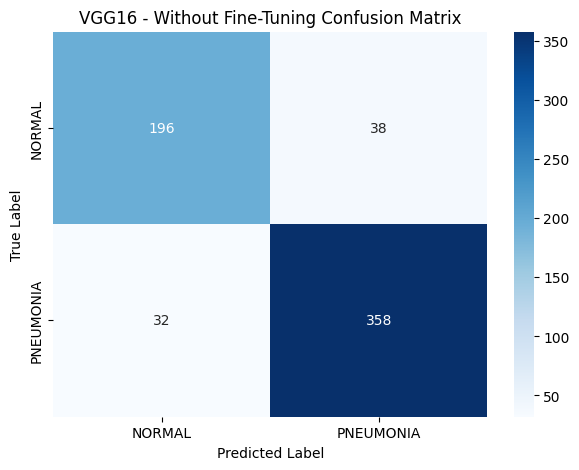

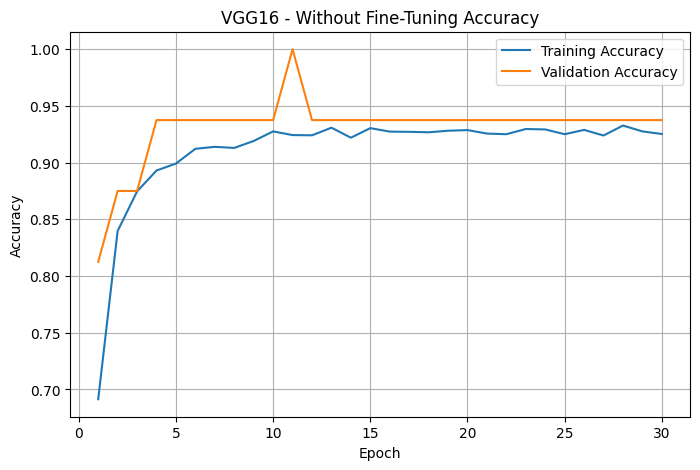

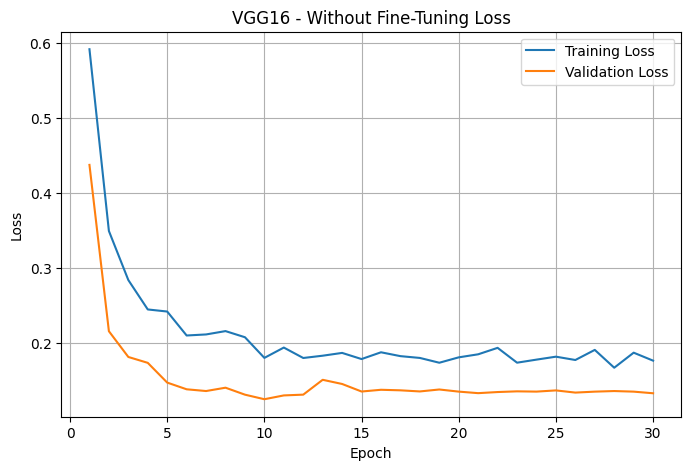


Saved model: vgg16_without_fine_tuning.keras


In [69]:
vgg16_result = train_and_evaluate(
    "VGG16",
    False
)